In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error, r2_score

In [60]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [62]:
df = pd.read_excel('dataset/kerala_land_price_dataset.xlsx', sheet_name='Land_Data')

In [63]:
df.head()

,Year,District,Place,Land_Type,Road_Access,Distance_Town_km,Distance_Highway_m,Area_Cent,Land_Price_Per_Cent_INR,Source,Data_Status
0,2010,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,1.0,500,1,350000,NaN,Actual price required
1,2011,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,1.5,530,1,457000,NaN,Actual price required
2,2012,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,2.0,532,1,525000,NaN,Actual price required
3,2013,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,1.0,534,1,600000,NaN,Actual price required
4,2014,Thiruvananthapuram,Kazhakkoottam,NH 66 Bypass Forntage,YES,1.0,536,1,776000,NaN,Actual price required


In [64]:
df.shape

(119, 11)

## 3. Data Cleaning

In [65]:
df['Place'] = df['Place'].str.strip() #remove extra space
df['Land_Type'] = df['Land_Type'].str.strip()
df['Land_Type'] = df['Land_Type'].str.replace('Forntage', 'Frontage') #correct the spelling

In [66]:
df['Place'].unique()

array(['Kazhakkoottam', 'Akkulam', 'Vizhinjam', 'Pattom', 'Karyavattom',
       'Kavadior', 'East Fort'], dtype=object)

In [67]:
df['Land_Type'].unique()

array(['NH 66 Bypass Frontage', 'NH HIGHWAY Frontage',
       'Prime / Main Road / Commercial'], dtype=object)

##### Useless columns drop

In [68]:
df = df.drop(columns=['District', 'Road_Access', 'Area_Cent', 'Source', 'Data_Status'])

In [69]:
df = df.rename(columns={'Land_Price_Per_Cent_INR': 'Price'})

In [70]:
df.head()

,Year,Place,Land_Type,Distance_Town_km,Distance_Highway_m,Price
0,2010,Kazhakkoottam,NH 66 Bypass Frontage,1.0,500,350000
1,2011,Kazhakkoottam,NH 66 Bypass Frontage,1.5,530,457000
2,2012,Kazhakkoottam,NH 66 Bypass Frontage,2.0,532,525000
3,2013,Kazhakkoottam,NH 66 Bypass Frontage,1.0,534,600000
4,2014,Kazhakkoottam,NH 66 Bypass Frontage,1.0,536,776000


In [71]:
df = df.sort_values(['Place', 'Year']).reset_index(drop=True)

In [72]:
df.groupby('Place')['Year'].agg(['min', 'max', 'count'])

,min,max,count
Place,,,
Akkulam,2010,2026,17
East Fort,2010,2026,17
Karyavattom,2010,2026,17
Kavadior,2010,2026,17
Kazhakkoottam,2010,2026,17
Pattom,2010,2026,17
Vizhinjam,2010,2026,17


####  Feature Engineering

In [73]:
df['t'] = df['Year'] - 2010
df['log_price'] = np.log(df['Price'])
df['YoY_%'] = df.groupby('Place')['Price'].pct_change() * 100

In [74]:
df.head()

,Year,Place,Land_Type,Distance_Town_km,Distance_Highway_m,Price,t,log_price,YoY_%
0,2010,Akkulam,NH 66 Bypass Frontage,1.0,300,350000,0,12.765688,NaN
1,2011,Akkulam,NH 66 Bypass Frontage,1.0,320,420000,1,12.948010,20.000000
2,2012,Akkulam,NH 66 Bypass Frontage,1.0,300,550000,2,13.217674,30.952381
3,2013,Akkulam,NH 66 Bypass Frontage,1.0,300,600000,3,13.304685,9.090909
4,2014,Akkulam,NH 66 Bypass Frontage,1.0,300,750000,4,13.527828,25.000000


####  Outlier Check (IQR method)

In [75]:
q1 = df['YoY_%'].quantile(0.25)
q3 = df['YoY_%'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print(lower, upper)

-9.166666666666682 37.5


In [76]:
df[(df['YoY_%'] < lower) | (df['YoY_%'] > upper)][['Place', 'Year', 'Price', 'YoY_%']]

,Place,Year,Price,YoY_%
18,East Fort,2011,1400000,40.000000
37,Karyavattom,2013,600000,50.000000
38,Karyavattom,2014,900000,50.000000
39,Karyavattom,2015,1500000,66.666667
53,Kavadior,2012,600000,50.000000


#### Save the Processed Data

In [77]:
df.to_csv('dataset/land_price_processed.csv', index=False)

In [78]:
df.shape

(119, 9)

####  Prepare for Modeling

In [79]:
pivot = df.pivot(index='Year', columns='Place', values='Price')

In [80]:
# Historical CAGR 2010-2026 (used later in the sanity check)
cagr = ((pivot.iloc[-1] / pivot.iloc[0]) ** (1 / 16) - 1) * 100

#### Train / Test Split (Time based)
- **Train:** 2010–2022
- **Test:** 2023–2026

In [81]:
train_df = df[df['Year'] < 2023]
test_df = df[df['Year'] >= 2023]

In [82]:
print(train_df.shape, test_df.shape)

(91, 9) (28, 9)


In [83]:
train = pivot[pivot.index < 2023]
test = pivot[pivot.index >= 2023]
places = pivot.columns

In [84]:
t_train = train.index.values - 2010
t_test = test.index.values - 2010
actual = test.values

#### Model Building

In [85]:
pred_naive = np.tile(train.values[-1], (len(test), 1))

#### Linear model

In [86]:
coef_lin = np.polyfit(t_train, train.values, 1)
pred_lin = np.clip(np.vander(t_test, 2) @ coef_lin, 0, None)

### Compound growth model

In [87]:
coef_comp = np.polyfit(t_train, np.log(train.values), 1)
pred_comp = np.exp(np.vander(t_test, 2) @ coef_comp)

#### Polynomial (degree 2) model

In [88]:
coef_poly = np.polyfit(t_train, train.values, 2)
pred_poly = np.clip(np.vander(t_test, 3) @ coef_poly, 0, None)

#### Tree models (Random Forest, Gradient Boosting)

In [89]:
X = pd.get_dummies(df[['Place', 'Year']], columns=['Place'])
X_train = X[df['Year'] < 2023]
X_test = X[df['Year'] >= 2023]
Y_train = df.loc[df['Year'] < 2023, 'Price']

In [90]:
rf = RandomForestRegressor(n_estimators=300, random_state=42)
rf.fit(X_train, Y_train)

,n_estimators,300
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [91]:
gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, Y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [92]:
test_pred = test_df[['Place', 'Year']].copy()
test_pred['rf'] = rf.predict(X_test)
test_pred['gb'] = gb.predict(X_test)

In [93]:
pred_rf = test_pred.pivot(index='Year', columns='Place', values='rf').values
pred_gb = test_pred.pivot(index='Year', columns='Place', values='gb').values

### Model Evaluation

In [94]:
m_naive = pd.DataFrame({'MAE': mean_absolute_error(actual, pred_naive, multioutput='raw_values'),
                        'RMSE': root_mean_squared_error(actual, pred_naive, multioutput='raw_values'),
                        'MAPE_%': mean_absolute_percentage_error(actual, pred_naive, multioutput='raw_values') * 100,
                        'R2': r2_score(actual, pred_naive, multioutput='raw_values')}, index=places)

In [95]:
m_lin = pd.DataFrame({'MAE': mean_absolute_error(actual, pred_lin, multioutput='raw_values'),
                      'RMSE': root_mean_squared_error(actual, pred_lin, multioutput='raw_values'),
                      'MAPE_%': mean_absolute_percentage_error(actual, pred_lin, multioutput='raw_values') * 100,
                      'R2': r2_score(actual, pred_lin, multioutput='raw_values')}, index=places)

In [96]:
m_comp = pd.DataFrame({'MAE': mean_absolute_error(actual, pred_comp, multioutput='raw_values'),
                       'RMSE': root_mean_squared_error(actual, pred_comp, multioutput='raw_values'),
                       'MAPE_%': mean_absolute_percentage_error(actual, pred_comp, multioutput='raw_values') * 100,
                       'R2': r2_score(actual, pred_comp, multioutput='raw_values')}, index=places)

In [97]:
m_poly = pd.DataFrame({'MAE': mean_absolute_error(actual, pred_poly, multioutput='raw_values'),
                       'RMSE': root_mean_squared_error(actual, pred_poly, multioutput='raw_values'),
                       'MAPE_%': mean_absolute_percentage_error(actual, pred_poly, multioutput='raw_values') * 100,
                       'R2': r2_score(actual, pred_poly, multioutput='raw_values')}, index=places)

In [98]:
m_rf = pd.DataFrame({'MAE': mean_absolute_error(actual, pred_rf, multioutput='raw_values'),
                     'RMSE': root_mean_squared_error(actual, pred_rf, multioutput='raw_values'),
                     'MAPE_%': mean_absolute_percentage_error(actual, pred_rf, multioutput='raw_values') * 100,
                     'R2': r2_score(actual, pred_rf, multioutput='raw_values')}, index=places)

In [99]:
m_gb = pd.DataFrame({'MAE': mean_absolute_error(actual, pred_gb, multioutput='raw_values'),
                     'RMSE': root_mean_squared_error(actual, pred_gb, multioutput='raw_values'),
                     'MAPE_%': mean_absolute_percentage_error(actual, pred_gb, multioutput='raw_values') * 100,
                     'R2': r2_score(actual, pred_gb, multioutput='raw_values')}, index=places)

#### model tabel (place wise)

In [100]:
comparison = pd.concat({'Naive (last value)': m_naive,
                        'Linear': m_lin,
                        'Compound growth': m_comp,
                        'Polynomial (deg 2)': m_poly,
                        'Random Forest (global)': m_rf,
                        'Gradient Boosting (global)': m_gb}, names=['Model', 'Place'])
comparison

MAE          RMSE  \
Model                      Place                                       
Naive (last value)         Akkulam        9.362500e+05  1.035739e+06   
                           East Fort      3.625000e+06  4.069705e+06   
                           Karyavattom    1.075000e+06  1.177922e+06   
                           Kavadior       8.000000e+05  9.300538e+05   
                           Kazhakkoottam  5.865000e+05  7.233941e+05   
                           Pattom         7.675000e+05  9.272136e+05   
                           Vizhinjam      5.000000e+05  5.787918e+05   
Linear                     Akkulam        4.594368e+05  5.141942e+05   
                           East Fort      2.806868e+06  3.021049e+06   
                           Karyavattom    2.252747e+05  2.296815e+05   
                           Kavadior       2.217033e+05  2.930856e+05   
                           Kazhakkoottam  3.840549e+05  4.908961e+05   
                           Pattom         6.010082e+05  6.865736e+05   
                           Vizhinjam      1.752747e+05  2.102307e+05   
Compound growth            Akkulam        1.150233e+06  1.224759e+06   
                           East Fort      3.256118e+06  3.517619e+06   
                           Karyavattom    5.344072e+06  5.749994e+06   
                           Kavadior       2.483936e+06  2.614370e+06   
                           Kazhakkoottam  2.745986e+05  2.990555e+05   
                           Pattom         1.367686e+05  1.508546e+05   
                           Vizhinjam      7.507445e+05  7.767701e+05   
Polynomial (deg 2)         Akkulam        1.652835e+05  1.749664e+05   
                           East Fort      6.152597e+05  6.757266e+05   
                           Karyavattom    3.217782e+05  3.437963e+05   
                           Kavadior       1.215784e+05  1.792358e+05   
                           Kazhakkoottam  1.755130e+05  2.907908e+05   
                           Pattom         4.388247e+05  5.213756e+05   
                           Vizhinjam      6.288711e+04  8.480156e+04   
Random Forest (global)     Akkulam        8.093833e+05  9.226557e+05   
                           East Fort      4.198333e+06  4.587797e+06   
                           Karyavattom    1.163467e+06  1.259178e+06   
                           Kavadior       8.479000e+05  9.715629e+05   
                           Kazhakkoottam  5.342567e+05  6.817235e+05   
                           Pattom         9.839200e+05  1.112999e+06   
                           Vizhinjam      4.205667e+05  5.117385e+05   
Gradient Boosting (global) Akkulam        9.084299e+05  1.010662e+06   
                           East Fort      3.650794e+06  4.092698e+06   
                           Karyavattom    1.064493e+06  1.168341e+06   
                           Kavadior       8.469367e+05  9.707223e+05   
                           Kazhakkoottam  5.676520e+05  7.081988e+05   
                           Pattom         8.248870e+05  9.752473e+05   
                           Vizhinjam      4.788509e+05  5.606230e+05   

                                              MAPE_%          R2  
Model                      Place                                  
Naive (last value)         Akkulam         26.717916   -4.467885  
                           East Fort       27.083333   -3.840183  
                           Karyavattom     23.053032   -4.983827  
                           Kavadior        19.831731   -2.844444  
                           Kazhakkoottam   23.005827   -1.918294  
                           Pattom          16.777696   -2.176299  
                           Vizhinjam       18.884994   -2.941176  
Linear                     Akkulam         13.048626   -0.347636  
                           East Fort       21.353938   -1.667175  
                           Karyavattom      5.082638    0.772491  
                           Kavadior         5.347486    0.618226  
           

In [101]:
summary = comparison.groupby('Model').mean().sort_values('RMSE')
summary

,MAE,RMSE,MAPE_%,R2
Model,,,,
Polynomial (deg 2),2.715892e+05,3.243847e+05,5.483923,0.642506
Linear,6.962316e+05,7.779587e+05,11.381915,-0.175640
Naive (last value),1.184321e+06,1.348974e+06,22.193504,-3.310301
Gradient Boosting (global),1.191721e+06,1.355213e+06,22.199784,-3.312107
Random Forest (global),1.279690e+06,1.435379e+06,22.715320,-3.538934
Compound growth,1.913781e+06,2.047632e+06,40.517890,-26.415414


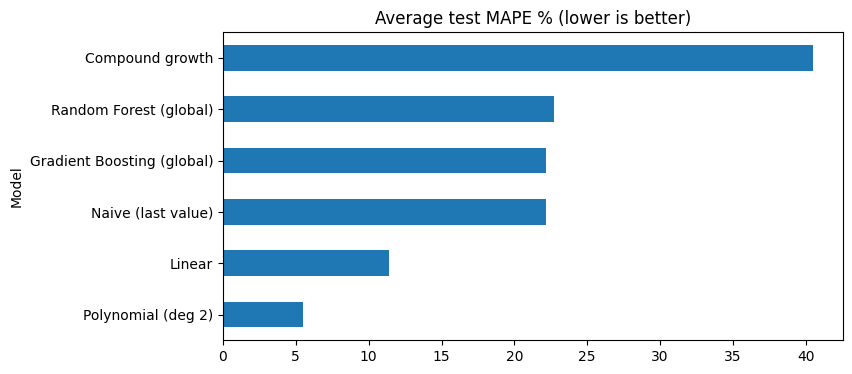

In [102]:
summary['MAPE_%'].sort_values().plot(kind='barh', figsize=(8, 4), title='Average test MAPE % (lower is better)')
plt.show()

In [103]:
rmse_table = comparison['RMSE'].unstack(level=0)
rmse_table

Model,Naive (last value),Linear,Compound growth,Polynomial (deg 2),Random Forest (global),Gradient Boosting (global)
Place,,,,,,
Akkulam,1.035739e+06,5.141942e+05,1.224759e+06,174966.379699,9.226557e+05,1.010662e+06
East Fort,4.069705e+06,3.021049e+06,3.517619e+06,675726.570513,4.587797e+06,4.092698e+06
Karyavattom,1.177922e+06,2.296815e+05,5.749994e+06,343796.266063,1.259178e+06,1.168341e+06
Kavadior,9.300538e+05,2.930856e+05,2.614370e+06,179235.820682,9.715629e+05,9.707223e+05
Kazhakkoottam,7.233941e+05,4.908961e+05,2.990555e+05,290790.833161,6.817235e+05,7.081988e+05
Pattom,9.272136e+05,6.865736e+05,1.508546e+05,521375.553217,1.112999e+06,9.752473e+05
Vizhinjam,5.787918e+05,2.102307e+05,7.767701e+05,84801.563655,5.117385e+05,5.606230e+05


In [104]:
eq_rmse = rmse_table[['Linear', 'Compound growth', 'Polynomial (deg 2)']]
best_model = eq_rmse.idxmin(axis=1)
best_rmse = eq_rmse.min(axis=1)
pd.DataFrame({'Best model': best_model, 'RMSE': best_rmse})

,Best model,RMSE
Place,,
Akkulam,Polynomial (deg 2),174966.379699
East Fort,Polynomial (deg 2),675726.570513
Karyavattom,Linear,229681.502436
Kavadior,Polynomial (deg 2),179235.820682
Kazhakkoottam,Polynomial (deg 2),290790.833161
Pattom,Compound growth,150854.604101
Vizhinjam,Polynomial (deg 2),84801.563655


In [105]:
t_all = pivot.index.values - 2010
final_lin = np.polyfit(t_all, pivot.values, 1)
final_comp = np.polyfit(t_all, np.log(pivot.values), 1)
final_poly = np.polyfit(t_all, pivot.values, 2)

#### Equations (t = Year − 2010)

In [106]:
eq_poly = pd.DataFrame(final_poly.T, index=places, columns=['c2 (t²)', 'c1 (t)', 'c0 (constant)'])
eq_poly

,c2 (t²),c1 (t),c0 (constant)
Place,,,
Akkulam,9020.252838,78653.895769,3.190454e+05
East Fort,46375.128999,107262.641899,1.260888e+06
Karyavattom,1535.087719,285977.812178,-2.321981e+03
Kavadior,4192.466460,184636.222910,2.627967e+05
Kazhakkoottam,6961.816305,29179.566563,4.418060e+05
Pattom,9191.305470,66902.347781,1.344888e+06
Vizhinjam,3341.073271,97768.317853,3.944272e+05


In [107]:
eq_lin = pd.DataFrame(final_lin.T, index=places, columns=['b1 (t)', 'b0 (constant)'])
eq_lin

,b1 (t),b0 (constant)
Place,,
Akkulam,222977.941176,-41764.705882
East Fort,849264.705882,-594117.647059
Karyavattom,310539.215686,-63725.490196
Kavadior,251715.686275,95098.039216
Kazhakkoottam,140568.627451,163333.333333
Pattom,213963.235294,977235.294118
Vizhinjam,151225.490196,260784.313725


In [108]:
eq_comp = pd.DataFrame({'Start price': np.exp(final_comp[1]),
                        'Yearly growth %': (np.exp(final_comp[0]) - 1) * 100}, index=places)
eq_comp

,Start price,Yearly growth %
Place,,
Akkulam,4.031980e+05,16.389738
East Fort,1.269204e+06,17.676247
Karyavattom,3.907077e+05,20.355000
Kavadior,4.901360e+05,16.432594
Kazhakkoottam,4.199832e+05,12.711470
Pattom,1.282220e+06,8.593851
Vizhinjam,4.913985e+05,12.501326


#### Forecast 2027–2040 + Uncertainty Band

In [109]:
future_years = np.arange(2027, 2041)
t_future = future_years - 2010
horizon = (future_years - 2026).reshape(-1, 1)

In [110]:
fc_lin = np.clip(np.vander(t_future, 2) @ final_lin, 0, None)
fc_comp = np.exp(np.vander(t_future, 2) @ final_comp)
fc_poly = np.clip(np.vander(t_future, 3) @ final_poly, 0, None)

In [111]:
fc_best = np.where(best_model.values == 'Linear', fc_lin,
          np.where(best_model.values == 'Compound growth', fc_comp, fc_poly))
forecast = pd.DataFrame(fc_best, index=future_years, columns=places)
forecast

Place,Akkulam,East Fort,Karyavattom,Kavadior,Kazhakkoottam,Pattom,Vizhinjam
2027,4.263015e+06,1.648676e+07,5.215441e+06,4.613235e+06,2.949824e+06,5.207767e+06,3.022059e+06
2028,4.657377e+06,1.821716e+07,5.525980e+06,4.944608e+06,3.222667e+06,5.655315e+06,3.236765e+06
2029,5.069781e+06,2.004030e+07,5.836520e+06,5.284365e+06,3.509433e+06,6.141324e+06,3.458153e+06
2030,5.500224e+06,2.195619e+07,6.147059e+06,5.632508e+06,3.810124e+06,6.669100e+06,3.686223e+06
2031,5.948709e+06,2.396483e+07,6.457598e+06,5.989035e+06,4.124738e+06,7.242233e+06,3.920975e+06
2032,6.415233e+06,2.606623e+07,6.768137e+06,6.353947e+06,4.453276e+06,7.864619e+06,4.162410e+06
2033,6.899799e+06,2.826037e+07,7.078676e+06,6.727245e+06,4.795737e+06,8.540493e+06,4.410526e+06
2034,7.402405e+06,3.054727e+07,7.389216e+06,7.108927e+06,5.152122e+06,9.274450e+06,4.665325e+06
2035,7.923051e+06,3.292691e+07,7.699755e+06,7.498994e+06,5.522430e+06,1.007148e+07,4.926806e+06
2036,8.461738e+06,3.539930e+07,8.010294e+06,7.897446e+06,5.906663e+06,1.093701e+07,5.194969e+06


In [112]:
band = 1.96 * best_rmse.values * np.sqrt(horizon)
lower_df = pd.DataFrame(np.maximum(fc_best - band, 0), index=future_years, columns=places)
upper_df = pd.DataFrame(fc_best + band, index=future_years, columns=places)

In [113]:
lower_df.head()

Place,Akkulam,East Fort,Karyavattom,Kavadior,Kazhakkoottam,Pattom,Vizhinjam
2027,3.920081e+06,1.516234e+07,4.765265e+06,4.261933e+06,2.379873e+06,4.912092e+06,2.855848e+06
2028,4.172395e+06,1.634414e+07,4.889336e+06,4.447791e+06,2.416636e+06,5.237167e+06,3.001707e+06
2029,4.475801e+06,1.774633e+07,5.056792e+06,4.675892e+06,2.522251e+06,5.629200e+06,3.170267e+06
2030,4.814356e+06,1.930734e+07,5.246707e+06,4.929903e+06,2.670224e+06,6.077750e+06,3.353801e+06
2031,5.181885e+06,2.100333e+07,5.450974e+06,5.203499e+06,2.850291e+06,6.581083e+06,3.549316e+06


In [114]:
upper_df.head()

Place,Akkulam,East Fort,Karyavattom,Kavadior,Kazhakkoottam,Pattom,Vizhinjam
2027,4.605949e+06,1.781119e+07,5.665617e+06,4.964538e+06,3.519774e+06,5.503442e+06,3.188270e+06
2028,5.142360e+06,2.009018e+07,6.162625e+06,5.441424e+06,4.028698e+06,6.073462e+06,3.471823e+06
2029,5.663760e+06,2.233427e+07,6.616247e+06,5.892839e+06,4.496616e+06,6.653448e+06,3.746039e+06
2030,6.186093e+06,2.460504e+07,7.047410e+06,6.335112e+06,4.950024e+06,7.260450e+06,4.018645e+06
2031,6.715533e+06,2.692634e+07,7.464222e+06,6.774571e+06,5.399185e+06,7.903382e+06,4.292634e+06


#### Sanity Check

In [115]:
check = pd.DataFrame({'Price_2026': pivot.loc[2026],
                      'Forecast_2040': forecast.loc[2040],
                      'Forecast_CAGR_%': ((forecast.loc[2040] / pivot.loc[2026]) ** (1 / 14) - 1) * 100,
                      'Historical_CAGR_%': cagr})
check

,Price_2026,Forecast_2040,Forecast_CAGR_%,Historical_CAGR_%
Place,,,,
Akkulam,3900000,1.079689e+07,7.544486,16.261865
East Fort,15000000,4.621638e+07,8.369602,18.441992
Karyavattom,5000000,9.252451e+06,4.494135,20.590855
Kavadior,4500000,9.575103e+06,5.541592,17.306352
Kazhakkoottam,3000000,7.582828e+06,6.847655,14.370976
Pattom,5000000,1.520966e+07,8.270635,9.329358
Vizhinjam,2900000,6.334443e+06,5.739307,13.180374


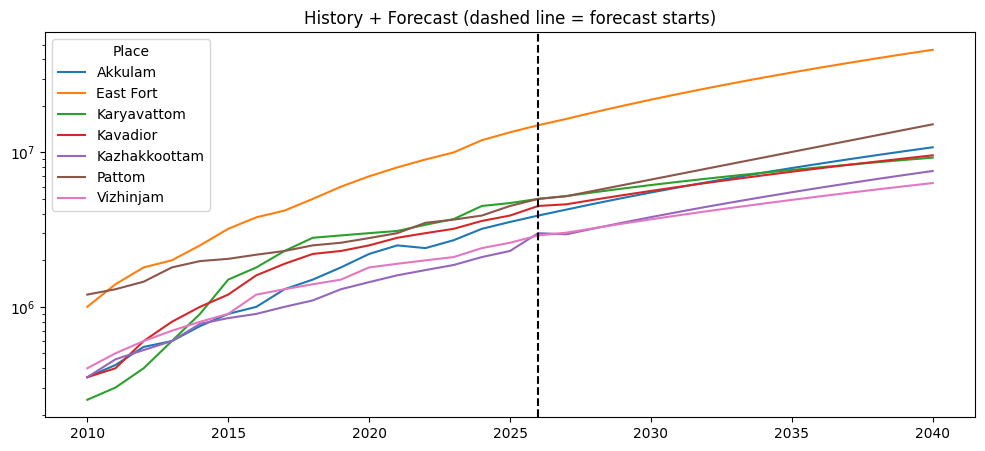

In [116]:
all_prices = pd.concat([pivot, forecast])
all_prices.plot(figsize=(12, 5), logy=True)
plt.axvline(2026, color='black', linestyle='--')
plt.title('History + Forecast (dashed line = forecast starts)')
plt.show()

####  Save the Models

In [58]:
joblib.dump(final_lin, 'land_linear_coef.pkl')
joblib.dump(final_comp, 'land_compound_coef.pkl')
joblib.dump(final_poly, 'land_poly_coef.pkl')
joblib.dump(best_model, 'land_best_model.pkl')
joblib.dump(forecast, 'land_forecast.pkl')

['land_forecast.pkl']

In [117]:
forecast.to_csv('future_predictions.csv')
comparison.to_csv('model_comparison.csv')
summary.to_csv('model_summary.csv')

In [118]:
lin_c = joblib.load('land_linear_coef.pkl')
comp_c = joblib.load('land_compound_coef.pkl')
poly_c = joblib.load('land_poly_coef.pkl')
best = joblib.load('land_best_model.pkl')

In [119]:
t = 2035 - 2010
p_lin = lin_c[0] * t + lin_c[1]
p_comp = np.exp(comp_c[0] * t + comp_c[1])
p_poly = poly_c[0] * t**2 + poly_c[1] * t + poly_c[2]

In [120]:
p_2035 = np.where(best.values == 'Linear', p_lin,
         np.where(best.values == 'Compound growth', p_comp, p_poly))
pd.DataFrame({'Model': best, 'Price_2035': p_2035})

,Model,Price_2035
Place,,
Akkulam,Polynomial (deg 2),7.923051e+06
East Fort,Polynomial (deg 2),3.292691e+07
Karyavattom,Linear,7.699755e+06
Kavadior,Polynomial (deg 2),7.498994e+06
Kazhakkoottam,Polynomial (deg 2),5.522430e+06
Pattom,Compound growth,1.007148e+07
Vizhinjam,Polynomial (deg 2),4.926806e+06
